# Практическое занятие №7-8
## Практическая работа: «Бинарная логистическая регрессия». Стохастический градиентный спуск. Алгоритмы оптимизации Adagrad и Adam

**Дисциплина:** «Алгоритмы машинного обучения для решения прикладных задач»

**Цель работы:** реализовать модель бинарной логистической регрессии, обучаемую
(а) максимизацией логарифмического правдоподобия методом градиентного подъёма и
(б) минимизацией функции потерь (кросс-энтропии) методом градиентного спуска; сравнить их по времени работы, accuracy и F1;
применить реализацию к задаче классификации рисковости договоров страхования (`insclass_train.csv`)
и сравнить полный градиентный спуск со стохастическим (mini-batch SGD) и адаптивными методами Adagrad и Adam.

## Часть 1. Задача бинарной классификации: расходы на рекламу → наличие эффекта

In [1]:
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
%matplotlib inline
plt.rcParams['figure.figsize'] = (9, 5)
RANDOM_STATE = 42

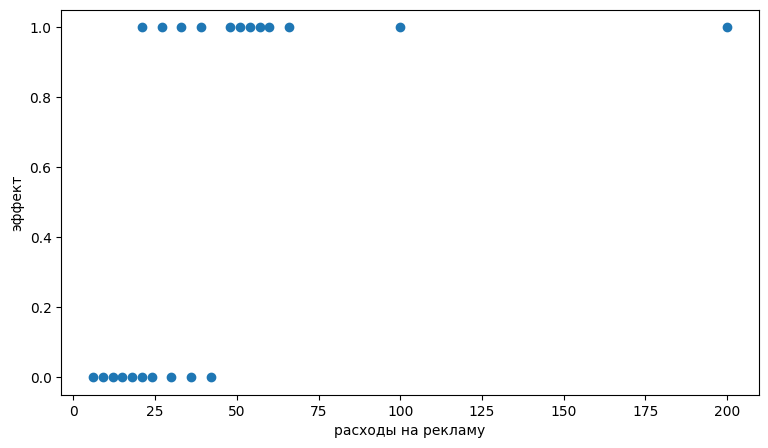

In [2]:
# Исходные данные: x - расходы на рекламу, Y - наличие эффекта (1 - есть, 0 - нет)
x = pd.DataFrame(np.array([39, 36, 60, 21, 27, 12, 51, 57, 54, 42, 18, 9, 48, 66, 6, 30, 24, 33, 15, 21, 100, 200]))
Y = pd.DataFrame(np.array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1]))
plt.scatter(x, Y)
plt.xlabel('расходы на рекламу'); plt.ylabel('эффект');

Попробуем разделить точки прямой (линейная регрессия). Значения прямой выходят за пределы [0, 1] и плохо интерпретируются как вероятность, а точки при больших x «тянут» прямую на себя:

Y = 0.266493 + 0.006333 * x


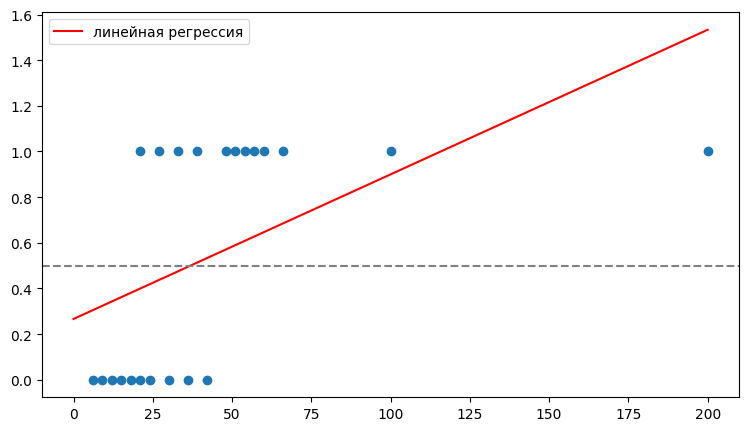

In [3]:
a1 = (((x - x.mean()) * (Y - Y.mean())).mean() / ((x - x.mean()) ** 2).mean()).item()
a0 = (Y.mean() - a1 * x.mean()).item()
print(f'Y = {a0:.6f} + {a1:.6f} * x')
x_space = np.linspace(0, 200, 50)
plt.plot(x_space, a0 + a1 * x_space, 'r', label='линейная регрессия')
plt.axhline(0.5, ls='--', c='gray')
plt.scatter(x, Y); plt.legend();

### Функция логистической регрессии

Сигмоида $g(z) = \dfrac{1}{1+e^{-z}}$ переводит линейную комбинацию $z = \theta^T x$ в вероятность $h_\theta(x) \in (0, 1)$.

**Логарифмическое правдоподобие** (максимизируется градиентным подъёмом):
$$\ell(\theta) = \sum_i \big[y_i \log h_\theta(x_i) + (1-y_i)\log(1-h_\theta(x_i))\big], \qquad \theta \leftarrow \theta + \alpha \frac{1}{n} X^T (y - h_\theta(X))$$

**Кросс-энтропия (log loss)** (минимизируется градиентным спуском):
$$J(\theta) = -\frac{1}{n}\sum_i \big[y_i \log h_\theta(x_i) + (1-y_i)\log(1-h_\theta(x_i))\big], \qquad \theta \leftarrow \theta - \alpha \frac{1}{n} X^T (h_\theta(X) - y)$$

<img src='images/ris1.png' width=320> <img src='images/ris3.png' width=420>

<img src='images/ris4.png' width=420>

Метрики: $accuracy = \dfrac{TP+TN}{TP+TN+FP+FN}$, $F_1 = \dfrac{2 \cdot precision \cdot recall}{precision + recall}$.

### Реализация класса логистической регрессии

In [4]:
class LogisticRegressionGD(object):
    """Бинарная логистическая регрессия.

    Rtype="LL" - максимизация логарифмического правдоподобия градиентным подъёмом;
    Rtype="CE" - минимизация кросс-энтропии градиентным спуском.
    Методы fit_sgd / fit_adagrad / fit_adam - стохастические и адаптивные оптимизаторы (минимизация CE).
    X должен содержать столбец единиц (свободный член).
    """
    EPS = 1e-12

    def __init__(self):
        self.a = None

    @staticmethod
    def _sigmoid(z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def predict_proba(self, X):
        return self._sigmoid(X @ self.a)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def coefs(self):
        return self.a

    def LogLikelihood(self, X, Y):
        p = np.clip(self.predict_proba(X), self.EPS, 1 - self.EPS)
        return (Y * np.log(p) + (1 - Y) * np.log(1 - p)).sum()

    def CrossEntropy(self, X, Y):
        p = np.clip(self.predict_proba(X), self.EPS, 1 - self.EPS)
        return (-Y * np.log(p) - (1 - Y) * np.log(1 - p)).mean()

    def accuracy(self, X, Y, threshold=0.5):
        return (self.predict(X, threshold) == Y).mean()

    # ---------- полный (batch) градиентный подъём / спуск ----------
    def fit(self, X, Y, alpha=0.01, max_steps=10000, Rtype="LL", epsilon=None, log_every=1):
        X, Y = np.asarray(X, dtype=float), np.asarray(Y, dtype=float).reshape(-1)
        n = X.shape[0]
        self.a = np.zeros(X.shape[1])
        steps, errors = [], []
        for step in range(1, max_steps + 1):
            p = self.predict_proba(X)
            if Rtype == "LL":
                grad = X.T @ (Y - p) / n          # градиент логарифмического правдоподобия
                self.a += alpha * grad            # шаг подъёма
            elif Rtype == "CE":
                grad = X.T @ (p - Y) / n          # градиент кросс-энтропии
                self.a -= alpha * grad            # шаг спуска
            else:
                raise ValueError(Rtype)
            if step % log_every == 0:
                err = self.LogLikelihood(X, Y) if Rtype == "LL" else self.CrossEntropy(X, Y)
                steps.append(step); errors.append(err)
            if epsilon is not None and np.linalg.norm(grad) < epsilon:
                break
        return steps, errors

    # ---------- стохастические и адаптивные методы ----------
    def _fit_stochastic(self, X, Y, update, lr, epochs, batch_size, X_mon, Y_mon, log_every, seed):
        X, Y = np.asarray(X, dtype=float), np.asarray(Y, dtype=float).reshape(-1)
        n = X.shape[0]
        rng = np.random.default_rng(seed)
        self.a = np.zeros(X.shape[1])
        state = {}
        X_mon = X if X_mon is None else X_mon
        Y_mon = Y if Y_mon is None else Y_mon
        history = {'iter': [0], 'time': [0.0], 'loss': [self.CrossEntropy(X_mon, Y_mon)]}
        it, t0, t_pause = 0, time.perf_counter(), 0.0
        for epoch in range(epochs):
            idx = rng.permutation(n)
            for start in range(0, n, batch_size):
                b = idx[start:start + batch_size]
                Xb, Yb = X[b], Y[b]
                grad = Xb.T @ (self.predict_proba(Xb) - Yb) / len(b)
                it += 1
                self.a -= update(grad, it, state, lr)
                if it % log_every == 0:
                    tp = time.perf_counter()
                    history['iter'].append(it)
                    history['time'].append(tp - t0 - t_pause)
                    history['loss'].append(self.CrossEntropy(X_mon, Y_mon))
                    t_pause += time.perf_counter() - tp   # время на мониторинг не учитываем
        return history

    def fit_sgd(self, X, Y, lr=0.1, epochs=5, batch_size=256, X_mon=None, Y_mon=None, log_every=50, seed=0):
        """Стохастический (mini-batch) градиентный спуск: w <- w - lr * g."""
        upd = lambda g, t, s, lr: lr * g
        return self._fit_stochastic(X, Y, upd, lr, epochs, batch_size, X_mon, Y_mon, log_every, seed)

    def fit_adagrad(self, X, Y, lr=0.1, epochs=5, batch_size=256, eps=1e-8, X_mon=None, Y_mon=None, log_every=50, seed=0):
        """Adagrad: G <- G + g^2;  w <- w - lr * g / (sqrt(G) + eps)."""
        def upd(g, t, s, lr):
            s['G'] = s.get('G', 0) + g ** 2
            return lr * g / (np.sqrt(s['G']) + eps)
        return self._fit_stochastic(X, Y, upd, lr, epochs, batch_size, X_mon, Y_mon, log_every, seed)

    def fit_adam(self, X, Y, lr=0.01, epochs=5, batch_size=256, beta1=0.9, beta2=0.999, eps=1e-8,
                 X_mon=None, Y_mon=None, log_every=50, seed=0):
        """Adam: m <- b1*m + (1-b1)*g;  v <- b2*v + (1-b2)*g^2;  w <- w - lr * m_hat / (sqrt(v_hat) + eps)."""
        def upd(g, t, s, lr):
            s['m'] = beta1 * s.get('m', 0) + (1 - beta1) * g
            s['v'] = beta2 * s.get('v', 0) + (1 - beta2) * g ** 2
            m_hat = s['m'] / (1 - beta1 ** t)
            v_hat = s['v'] / (1 - beta2 ** t)
            return lr * m_hat / (np.sqrt(v_hat) + eps)
        return self._fit_stochastic(X, Y, upd, lr, epochs, batch_size, X_mon, Y_mon, log_every, seed)

In [5]:
# Добавляем столбец единиц (свободный член)
intercept = np.ones((x.shape[0], 1))
x_ = np.concatenate((intercept, x.values), axis=1).astype(float)
y_ = Y.values.ravel()

### Сравнение способов (а) и (б) при одинаковом числе шагов и скорости обучения

In [6]:
ALPHA, STEPS = 0.01, 10000

start_time_CE = time.perf_counter()
regr_CE = LogisticRegressionGD()
steps_CE, errors_CE = regr_CE.fit(x_, y_, alpha=ALPHA, max_steps=STEPS, Rtype="CE")
time_CE = time.perf_counter() - start_time_CE
print(f"(б) Кросс-энтропия, градиентный спуск:   время обучения {time_CE:.3f} сек.")

start_time_LL = time.perf_counter()
regr_LL = LogisticRegressionGD()
steps_LL, errors_LL = regr_LL.fit(x_, y_, alpha=ALPHA, max_steps=STEPS, Rtype="LL")
time_LL = time.perf_counter() - start_time_LL
print(f"(а) Правдоподобие, градиентный подъём:   время обучения {time_LL:.3f} сек.")

(б) Кросс-энтропия, градиентный спуск:   время обучения 0.251 сек.
(а) Правдоподобие, градиентный подъём:   время обучения 0.220 сек.


Коэффициенты (CE): [-3.59893309  0.1121552 ]
Коэффициенты (LL): [-3.59893309  0.1121552 ]


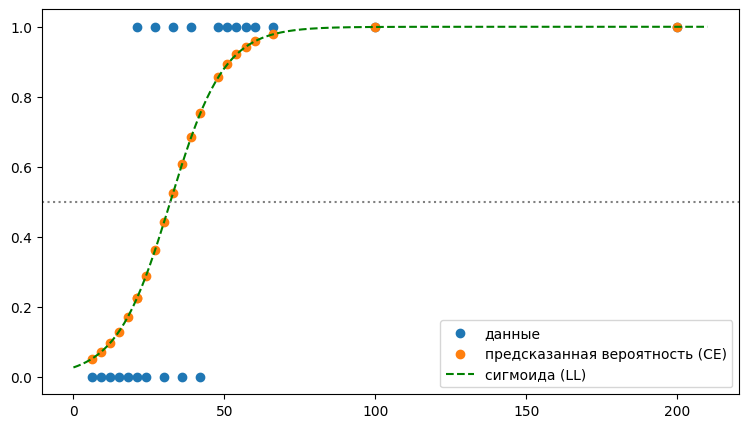

In [7]:
print('Коэффициенты (CE):', regr_CE.coefs())
print('Коэффициенты (LL):', regr_LL.coefs())
x_plot = np.linspace(0, 210, 300)
X_plot = np.c_[np.ones_like(x_plot), x_plot]
plt.scatter(x, Y, label='данные')
plt.scatter(x, regr_CE.predict_proba(x_), label='предсказанная вероятность (CE)')
plt.plot(x_plot, regr_LL.predict_proba(X_plot), 'g--', label='сигмоида (LL)')
plt.axhline(0.5, ls=':', c='gray'); plt.legend();

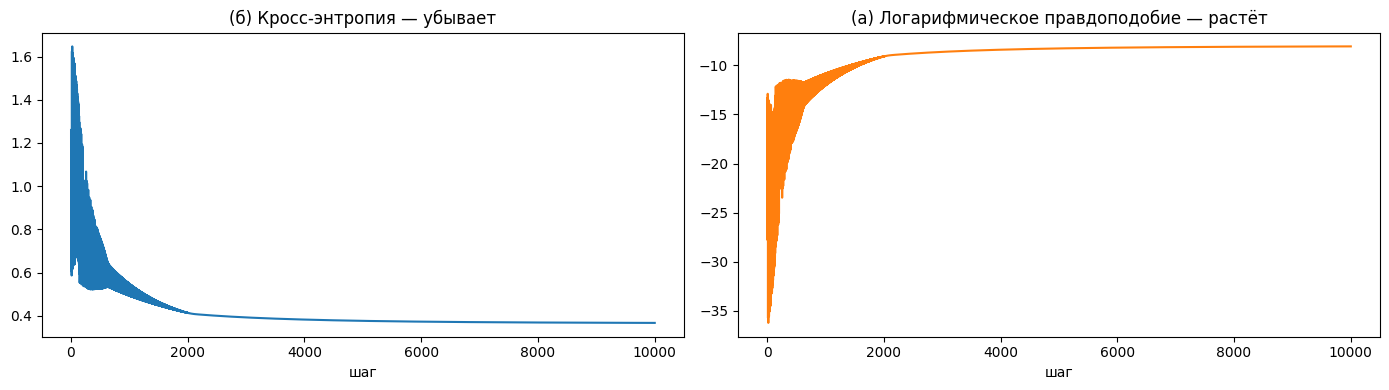

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(steps_CE, errors_CE, label='кросс-энтропия (CE), mean')
axes[0].set_title('(б) Кросс-энтропия — убывает'); axes[0].set_xlabel('шаг')
axes[1].plot(steps_LL, errors_LL, c='tab:orange', label='log-likelihood (LL), sum')
axes[1].set_title('(а) Логарифмическое правдоподобие — растёт'); axes[1].set_xlabel('шаг')
plt.tight_layout()

На первых ~2000 шагах заметны сильные колебания функции потерь: признак x не масштабирован (значения до 200), поэтому шаг α = 0.01 для коэффициента при x слишком велик. Это типичная проблема градиентного спуска, которую решают масштабированием признаков или адаптивными методами.

In [9]:
toy_results = pd.DataFrame({
    'Способ': ['(а) LL, градиентный подъём', '(б) CE, градиентный спуск'],
    'Время, с': [time_LL, time_CE],
    'Accuracy': [accuracy_score(y_, regr_LL.predict(x_)), accuracy_score(y_, regr_CE.predict(x_))],
    'F1': [f1_score(y_, regr_LL.predict(x_)), f1_score(y_, regr_CE.predict(x_))],
    'theta_0': [regr_LL.a[0], regr_CE.a[0]],
    'theta_1': [regr_LL.a[1], regr_CE.a[1]],
}).round(4)
toy_results

,Способ,"Время, с",Accuracy,F1,theta_0,theta_1
0,"(а) LL, градиентный подъём",0.2198,0.8182,0.8333,-3.5989,0.1122
1,"(б) CE, градиентный спуск",0.2507,0.8182,0.8333,-3.5989,0.1122


In [10]:
from sklearn.linear_model import LogisticRegression
sk = LogisticRegression(penalty=None, max_iter=10000).fit(x.values, y_)
print('sklearn (без регуляризации): theta_0 =', sk.intercept_[0].round(4), ' theta_1 =', sk.coef_[0][0].round(4),
      ' accuracy =', accuracy_score(y_, sk.predict(x.values)))

sklearn (без регуляризации): theta_0 = -4.0789  theta_1 = 0.1254  accuracy = 0.8181818181818182


**Вывод по части 1.** Способы (а) и (б) математически эквивалентны: градиент логарифмического правдоподобия равен градиенту
кросс-энтропии с обратным знаком, поэтому при одинаковых α и числе шагов они дают **совпадающие коэффициенты** и одинаковые
accuracy и F1. Разница во времени — только накладные расходы на вычисление разных функционалов и погрешность измерения.
Векторизованная реализация на NumPy работает в сотни раз быстрее варианта на pandas DataFrame из методички (~50 с).

## Часть 2. Классификация рисковости договоров страхования (`insclass_train.csv`)

Для 151 406 договоров страхования транспортных средств известны 28 признаков (`variable_1` … `variable_28`) и признак `target`
(1 — заключение договора является рисковым). Требуется построить модель и предсказать `target` для 22 624 договоров из `insclass_test.csv`.

In [11]:
from pathlib import Path

def find_file(name):
    for d in [Path('.'), Path('data')]:
        if (d / name).exists():
            return d / name
    return Path(name)

TRAIN_PATH, TEST_PATH = find_file('insclass_train.csv'), find_file('insclass_test.csv')

def make_synthetic_insclass(n, seed):
    """Синтетический набор данных той же структуры, что insclass (используется, только если исходные файлы отсутствуют)."""
    rng = np.random.default_rng(seed)
    d = {}
    kbm_levels = np.array([0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0, 1.4, 1.55, 2.3, 2.45])
    kbm_p = np.array([.20, .06, .06, .06, .06, .06, .07, .07, .08, .08, .14, .03, .015, .01, .005]); kbm_p /= kbm_p.sum()
    d['variable_1'] = rng.choice(kbm_levels, n, p=kbm_p)
    d['variable_2'] = rng.binomial(1, 0.04, n)
    d['variable_3'] = rng.binomial(1, 0.01, n)
    d['variable_4'] = rng.integers(1, 31, n)                                  # id года выпуска
    d['variable_5'] = rng.choice(16, n, p=np.r_[0.35, np.full(15, 0.65 / 15)])
    hp = np.clip(rng.lognormal(np.log(115), 0.35, n), 50, 450).round()
    d['variable_6'] = hp
    d['variable_7'] = np.clip(hp * 13 + rng.normal(0, 250, n), 800, 6000).round()
    d['variable_8'] = rng.binomial(1, 0.05, n)
    d['variable_10'] = (d['variable_4'] > 25).astype(int) * rng.binomial(1, 0.8, n)
    d['variable_9'] = np.where(d['variable_10'] == 1, rng.choice([100000, 150000], n), 0)
    d['variable_11'] = rng.binomial(1, 0.25, n)
    d['variable_12'] = ((31 - d['variable_4']) * 12 + rng.integers(0, 12, n))
    age = rng.integers(18, 80, n)
    exp_ = np.clip(age - 18 - rng.integers(0, 15, n), 0, None)
    d['variable_13'] = age
    d['variable_27'] = exp_
    d['variable_14'] = np.where((age < 22) & (exp_ < 3), 1.87, np.where(age < 22, 1.77, np.where(exp_ < 3, 1.63, 1.0)))
    d['variable_15'] = rng.choice([1.0, 0.7, 0.5], n, p=[0.93, 0.05, 0.02])
    d['variable_16'] = np.select([hp <= 70, hp <= 100, hp <= 120, hp <= 150], [1.0, 1.1, 1.2, 1.4], 1.6)
    d['variable_17'] = np.where(d['variable_11'] == 1, 1.87, 1.0)
    d['variable_18'] = rng.choice([0.64, 1.0, 1.3, 1.6, 1.8, 2.0], n, p=[.1, .25, .2, .2, .15, .1])
    d['variable_19'] = d['variable_1']
    d['variable_20'] = rng.choice(6, n, p=[.4, .25, .15, .1, .06, .04])
    brand = rng.zipf(1.6, n) % 80
    d['variable_21'] = brand
    d['variable_22'] = brand * 10 + rng.integers(0, 10, n)
    d['variable_23'] = (brand < 5).astype(int)
    d['variable_24'] = rng.binomial(1, 0.7, n)
    d['variable_25'] = rng.binomial(1, 0.6, n)
    d['variable_26'] = rng.binomial(1, 0.75, n)
    d['variable_28'] = rng.choice(6, n, p=[.85, .05, .04, .03, .02, .01])
    df = pd.DataFrame(d)[[f'variable_{i}' for i in range(1, 29)]]
    z = (-3.1 + 1.6 * (df.variable_1 - 0.8) + 0.9 * (df.variable_14 - 1) + 0.5 * df.variable_11
         + 0.6 * (df.variable_18 - 1.3) + 0.004 * (hp - 115) - 0.012 * (age - 45) - 0.5 * df.variable_25
         + 0.35 * (df.variable_20 == 1) + 0.45 * (df.variable_28 == 2) + 0.9 * df.variable_3
         + 0.3 * (df.variable_5 == 0) - 0.4 * df.variable_26 + rng.normal(0, 0.8, n))
    df['target'] = rng.binomial(1, 1 / (1 + np.exp(-z)))
    for col, frac in [('variable_9', 0.02), ('variable_27', 0.01), ('variable_7', 0.005)]:
        df.loc[rng.random(n) < frac, col] = np.nan
    return df

if TRAIN_PATH.exists():
    train_df = pd.read_csv(TRAIN_PATH)
    test_df = pd.read_csv(TEST_PATH) if TEST_PATH.exists() else None
    DATA_SOURCE = 'исходный файл insclass_train.csv' + (' и insclass_test.csv' if test_df is not None else ' (insclass_test.csv отсутствует)')
else:
    train_df = make_synthetic_insclass(151406, seed=1)
    test_df = make_synthetic_insclass(22624, seed=2).drop(columns='target')
    DATA_SOURCE = 'СИНТЕТИЧЕСКИЕ данные той же структуры (файлы insclass_*.csv не найдены)'
print('Источник данных:', DATA_SOURCE)
print('train:', train_df.shape, ' test:', None if test_df is None else test_df.shape)
train_df.head()

Источник данных: исходный файл insclass_train.csv (insclass_test.csv отсутствует)
train: (151406, 29)  test: None


,variable_1,variable_2,variable_3,variable_4,variable_5,variable_6,variable_7,variable_8,variable_9,variable_10,...,variable_20,variable_21,variable_22,variable_23,variable_24,variable_25,variable_26,variable_27,variable_28,target
0,w200,0,0,14,q2,98.0,NaN,0.0,NaN,0,...,C,j2,h45,0,0.0,0,1,19.323463,t1,0
1,w160,0,0,7,q11,106.0,NaN,0.0,NaN,0,...,C,j33,h234,0,1.0,0,1,41.177900,t1,0
2,w200,0,0,4,q3,123.0,NaN,0.0,NaN,0,...,B,j12,h28,0,0.0,0,1,3.614395,t1,0
3,w200,0,0,9,q3,102.0,NaN,0.0,NaN,0,...,C,j12,h64,0,1.0,0,0,49.041674,t1,0
4,w200,0,0,18,q20,117.0,NaN,0.0,NaN,0,...,C,j111,h991,0,1.0,0,0,17.909612,t1,0


In [12]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 151406 entries, 0 to 151405
Data columns (total 29 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   variable_1   151406 non-null  str    
 1   variable_2   151406 non-null  int64  
 2   variable_3   151406 non-null  int64  
 3   variable_4   151406 non-null  int64  
 4   variable_5   151406 non-null  str    
 5   variable_6   151295 non-null  float64
 6   variable_7   55767 non-null   float64
 7   variable_8   121507 non-null  float64
 8   variable_9   16970 non-null   float64
 9   variable_10  151406 non-null  int64  
 10  variable_11  151406 non-null  int64  
 11  variable_12  149878 non-null  float64
 12  variable_13  149749 non-null  float64
 13  variable_14  148479 non-null  float64
 14  variable_15  13 non-null      float64
 15  variable_16  151394 non-null  float64
 16  variable_17  151394 non-null  float64
 17  variable_18  151394 non-null  float64
 18  variable_19  151406 non-null  float

Доля рисковых договоров (target=1): 0.0955


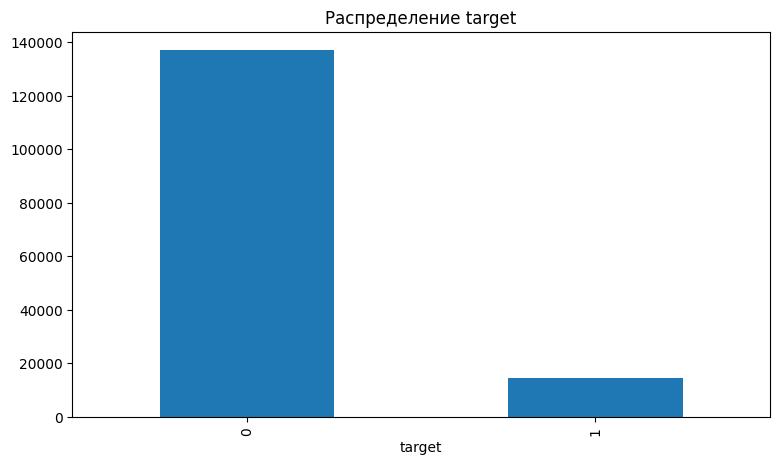

In [13]:
print('Доля рисковых договоров (target=1):', round(train_df['target'].mean(), 4))
train_df['target'].value_counts().plot.bar(title='Распределение target');

In [14]:
na = train_df.isna().sum(); na[na > 0]

variable_6        111
variable_7      95639
variable_8      29899
variable_9     134436
variable_12      1528
variable_13      1657
variable_14      2927
variable_15    151393
variable_16        12
variable_17        12
variable_18        12
variable_20         1
variable_24      2207
variable_27      2067
dtype: int64

In [15]:
nunique = train_df.drop(columns='target').nunique().sort_values()
nunique.to_frame('уникальных значений').T

,variable_3,variable_2,variable_8,variable_10,variable_11,variable_23,variable_24,variable_17,variable_25,variable_26,...,variable_5,variable_9,variable_4,variable_27,variable_13,variable_21,variable_12,variable_7,variable_6,variable_22
уникальных значений,1,2,2,2,2,2,2,2,2,2,...,39,57,62,73,77,192,579,742,1121,1475


### Предобработка признаков

По описанию признаков и типам данных:
* **категориальные**: `variable_4` (год выпуска), `variable_5` (страна), `variable_8` (руль), `variable_20` (канал продаж),
  `variable_21` (марка), `variable_22` (модель), `variable_24` (пол), `variable_28` (тип ТС), а также все строковые признаки
  (в исходных данных `variable_1` — бонус-малус — закодирован строками вида `w200`). Кодируются One-Hot, редкие категории объединяются (не более 20 на признак);
* **неинформативные** признаки (полностью пропущенные или константные) исключаются;
* **числовые** (включая бинарные индикаторы) — заполнение пропусков медианой с добавлением признака-индикатора пропуска
  (у `variable_7` и `variable_9` пропущено 63 % и 89 % значений, сам факт пропуска может быть информативен) и стандартизация,
  важная для сходимости градиентного спуска.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split

feature_cols = [c for c in train_df.columns if c.startswith('variable_')]
# столбцы без информации (все значения пропущены или одно значение) исключаем
dropped = [c for c in feature_cols if train_df[c].nunique(dropna=True) <= 1]
feature_cols = [c for c in feature_cols if c not in dropped]
print('Исключены неинформативные признаки:', dropped)
cat_ids = [4, 5, 8, 20, 21, 22, 24, 28]
cat_cols = [f'variable_{i}' for i in cat_ids if f'variable_{i}' in feature_cols]
cat_cols += [c for c in feature_cols if not pd.api.types.is_numeric_dtype(train_df[c]) and c not in cat_cols]
num_cols = [c for c in feature_cols if c not in cat_cols]

preprocess = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()), num_cols),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='infrequent_if_exist', max_categories=20,
                                        sparse_output=False)), cat_cols),
])

X_all = train_df[feature_cols]
y_all = train_df['target'].astype(int).values
X_tr_df, X_val_df, y_tr, y_val = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all,
                                                  random_state=RANDOM_STATE)
X_tr = preprocess.fit_transform(X_tr_df)
X_val = preprocess.transform(X_val_df)
add_bias = lambda M: np.c_[np.ones(M.shape[0]), M]
X_tr, X_val = add_bias(X_tr), add_bias(X_val)
print('Числовых признаков:', len(num_cols), '| категориальных:', len(cat_cols))
print('Матрица признаков после кодирования: train', X_tr.shape, ' validation', X_val.shape)

Исключены неинформативные признаки: ['variable_3']


Числовых признаков: 18 | категориальных: 9
Матрица признаков после кодирования: train (121124, 137)  validation (30282, 137)


### Обучение способами (а) и (б): одинаковые α и число шагов

In [17]:
ALPHA, STEPS = 0.5, 1500

t = time.perf_counter()
ins_LL = LogisticRegressionGD()
steps_ins_LL, err_ins_LL = ins_LL.fit(X_tr, y_tr, alpha=ALPHA, max_steps=STEPS, Rtype='LL', log_every=10)
time_ins_LL = time.perf_counter() - t

t = time.perf_counter()
ins_CE = LogisticRegressionGD()
steps_ins_CE, err_ins_CE = ins_CE.fit(X_tr, y_tr, alpha=ALPHA, max_steps=STEPS, Rtype='CE', log_every=10)
time_ins_CE = time.perf_counter() - t
print(f'(а) LL: {time_ins_LL:.2f} c   (б) CE: {time_ins_CE:.2f} c')
print('Макс. различие коэффициентов:', np.abs(ins_LL.a - ins_CE.a).max())

(а) LL: 17.12 c   (б) CE: 16.99 c
Макс. различие коэффициентов: 0.0


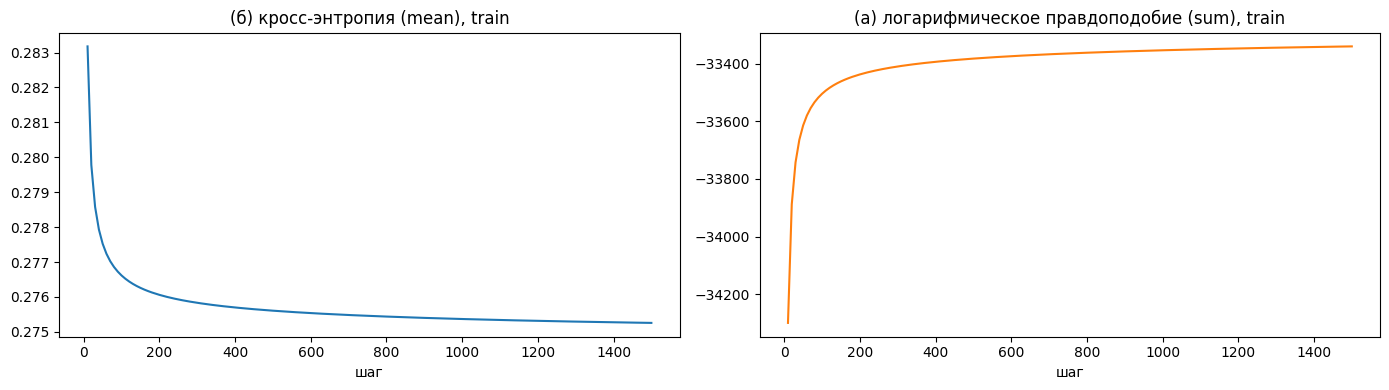

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(steps_ins_CE, err_ins_CE); axes[0].set_title('(б) кросс-энтропия (mean), train'); axes[0].set_xlabel('шаг')
axes[1].plot(steps_ins_LL, err_ins_LL, c='tab:orange'); axes[1].set_title('(а) логарифмическое правдоподобие (sum), train'); axes[1].set_xlabel('шаг')
plt.tight_layout()

### Оценка качества

Классы несбалансированы, поэтому при пороге 0.5 модель почти всегда предсказывает класс 0 — accuracy высокая, но F1 низкий.
Дополнительно подберём порог классификации, максимизирующий F1 (по обучающей выборке, чтобы не «подглядывать» в валидацию).

In [19]:
def best_threshold(model, X, y):
    p = model.predict_proba(X)
    grid = np.linspace(0.05, 0.6, 56)
    f1s = [f1_score(y, (p >= t).astype(int)) for t in grid]
    return grid[int(np.argmax(f1s))]

def evaluate(name, model, t_fit, thr=0.5):
    pred = model.predict(X_val, thr)
    p = model.predict_proba(X_val)
    return {'Модель': name, 'Время обучения, с': round(t_fit, 2), 'Порог': round(thr, 2),
            'Accuracy': accuracy_score(y_val, pred), 'Precision': precision_score(y_val, pred, zero_division=0),
            'Recall': recall_score(y_val, pred), 'F1': f1_score(y_val, pred), 'ROC AUC': roc_auc_score(y_val, p),
            'Log loss': model.CrossEntropy(X_val, y_val)}

thr_LL, thr_CE = best_threshold(ins_LL, X_tr, y_tr), best_threshold(ins_CE, X_tr, y_tr)
res_ab = pd.DataFrame([
    evaluate('(а) LL, градиентный подъём', ins_LL, time_ins_LL),
    evaluate('(б) CE, градиентный спуск', ins_CE, time_ins_CE),
    evaluate('(а) LL, подобранный порог', ins_LL, time_ins_LL, thr_LL),
    evaluate('(б) CE, подобранный порог', ins_CE, time_ins_CE, thr_CE),
]).round(4)
res_ab

,Модель,"Время обучения, с",Порог,Accuracy,Precision,Recall,F1,ROC AUC,Log loss
0,"(а) LL, градиентный подъём",17.12,0.50,0.9183,1.0000,0.1449,0.2531,0.6742,0.275
1,"(б) CE, градиентный спуск",16.99,0.50,0.9183,1.0000,0.1449,0.2531,0.6742,0.275
2,"(а) LL, подобранный порог",17.12,0.14,0.8824,0.3317,0.2282,0.2704,0.6742,0.275
3,"(б) CE, подобранный порог",16.99,0.14,0.8824,0.3317,0.2282,0.2704,0.6742,0.275


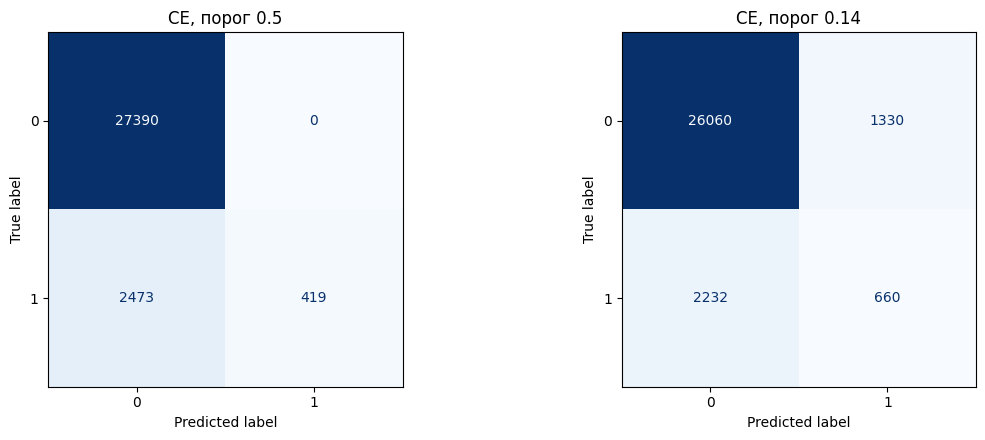

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_val, ins_CE.predict(X_val), ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('CE, порог 0.5')
ConfusionMatrixDisplay.from_predictions(y_val, ins_CE.predict(X_val, thr_CE), ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title(f'CE, порог {thr_CE:.2f}')
plt.tight_layout()

### Стохастический градиентный спуск, Adagrad и Adam

Полный градиентный спуск на каждом шаге использует все ~121 тыс. объектов. **Стохастический (mini-batch) градиентный спуск**
оценивает градиент по небольшой случайной подвыборке (batch = 256), поэтому шаг в сотни раз дешевле.
**Adagrad** адаптирует скорость обучения для каждого параметра, деля шаг на корень из суммы квадратов прошлых градиентов
(полезно для редких one-hot признаков). **Adam** сочетает инерцию (экспоненциальное среднее градиентов, momentum)
с адаптивной нормировкой (среднее квадратов градиентов, как в RMSProp) и коррекцией смещения.

Сравним методы по значению кросс-энтропии на валидационной выборке в зависимости от времени обучения (3 эпохи для стохастических методов).

In [21]:
EPOCHS, BATCH = 3, 256
optim_models, histories, times = {}, {}, {}
configs = {
    'SGD (lr=0.1)':     ('fit_sgd',     dict(lr=0.1)),
    'Adagrad (lr=0.1)': ('fit_adagrad', dict(lr=0.1)),
    'Adam (lr=0.005)':  ('fit_adam',    dict(lr=0.005)),
}
for name, (method, kw) in configs.items():
    m = LogisticRegressionGD()
    t = time.perf_counter()
    histories[name] = getattr(m, method)(X_tr, y_tr, epochs=EPOCHS, batch_size=BATCH,
                                         X_mon=X_val, Y_mon=y_val, log_every=50, **kw)
    times[name] = histories[name]['time'][-1]
    optim_models[name] = m
    print(f'{name:18s} время {times[name]:.2f} c, итераций {histories[name]["iter"][-1]}, val log loss {histories[name]["loss"][-1]:.4f}')

SGD (lr=0.1)       время 0.09 c, итераций 1400, val log loss 0.2754
Adagrad (lr=0.1)   время 0.09 c, итераций 1400, val log loss 0.2748


Adam (lr=0.005)    время 0.10 c, итераций 1400, val log loss 0.2751


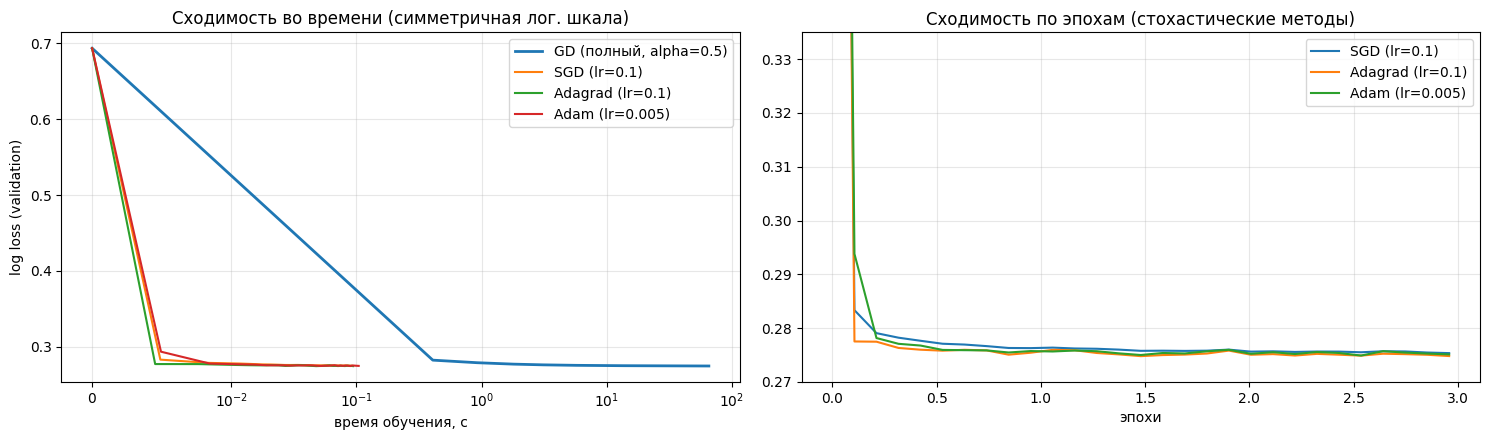

In [22]:
# Для сравнения — полный GD с той же записью val loss во времени
gd_hist = {'time': [0.0], 'loss': [None]}
m = LogisticRegressionGD(); m.a = np.zeros(X_tr.shape[1]); gd_hist['loss'][0] = m.CrossEntropy(X_val, y_val)
t0, t_pause, n = time.perf_counter(), 0.0, X_tr.shape[0]
for step in range(1, STEPS + 1):
    m.a -= ALPHA * X_tr.T @ (m.predict_proba(X_tr) - y_tr) / n
    if step % 10 == 0:
        tp = time.perf_counter()
        gd_hist['time'].append(tp - t0 - t_pause); gd_hist['loss'].append(m.CrossEntropy(X_val, y_val))
        t_pause += time.perf_counter() - tp

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(gd_hist['time'], gd_hist['loss'], label=f'GD (полный, alpha={ALPHA})', lw=2)
for name, h in histories.items():
    axes[0].plot(h['time'], h['loss'], label=name)
axes[0].set_xlabel('время обучения, с'); axes[0].set_ylabel('log loss (validation)')
axes[0].set_xscale('symlog', linthresh=0.01); axes[0].set_title('Сходимость во времени (симметричная лог. шкала)'); axes[0].legend(); axes[0].grid(alpha=.3)
for name, h in histories.items():
    axes[1].plot(np.array(h['iter']) * BATCH / X_tr.shape[0], h['loss'], label=name)
axes[1].set_xlabel('эпохи'); axes[1].set_title('Сходимость по эпохам (стохастические методы)')
axes[1].set_ylim(min(gd_hist['loss']) - 0.005, min(gd_hist['loss']) + 0.06); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout()

In [23]:
rows = [evaluate('GD: (б) CE, полный градиентный спуск', ins_CE, time_ins_CE, thr_CE)]
for name, mdl in optim_models.items():
    rows.append(evaluate(name, mdl, times[name], best_threshold(mdl, X_tr, y_tr)))
sk_model = LogisticRegression(max_iter=1000)
t = time.perf_counter(); sk_model.fit(X_tr[:, 1:], y_tr); t_sk = time.perf_counter() - t
class SkWrap:
    def __init__(s, m): s.m = m
    def predict_proba(s, X): return s.m.predict_proba(X[:, 1:])[:, 1]
    def predict(s, X, thr=0.5): return (s.predict_proba(X) >= thr).astype(int)
    def CrossEntropy(s, X, y):
        p = np.clip(s.predict_proba(X), 1e-12, 1 - 1e-12); return (-y * np.log(p) - (1 - y) * np.log(1 - p)).mean()
skw = SkWrap(sk_model)
rows.append(evaluate('sklearn LogisticRegression (lbfgs, L2)', skw, t_sk, best_threshold(skw, X_tr, y_tr)))
res_opt = pd.DataFrame(rows).round(4)
res_opt

,Модель,"Время обучения, с",Порог,Accuracy,Precision,Recall,F1,ROC AUC,Log loss
0,"GD: (б) CE, полный градиентный спуск",16.99,0.14,0.8824,0.3317,0.2282,0.2704,0.6742,0.2750
1,SGD (lr=0.1),0.09,0.14,0.8793,0.3211,0.2365,0.2724,0.6727,0.2754
2,Adagrad (lr=0.1),0.09,0.14,0.8737,0.3076,0.2576,0.2804,0.6752,0.2748
3,Adam (lr=0.005),0.10,0.14,0.8613,0.2788,0.2849,0.2819,0.6737,0.2751
4,"sklearn LogisticRegression (lbfgs, L2)",0.58,0.14,0.8798,0.3244,0.2393,0.2754,0.6749,0.2748


In [24]:
pd.concat([res_ab, res_opt]).to_csv('results_pr7_8.csv', index=False)

### Предсказание для тестового набора `insclass_test.csv`

In [25]:
best_name = res_opt.iloc[:-1].sort_values('Log loss').iloc[0]['Модель']
best_model = {**{'GD: (б) CE, полный градиентный спуск': ins_CE}, **optim_models}[best_name]
best_thr = res_opt.set_index('Модель').loc[best_name, 'Порог']
print('Для предсказания используется:', best_name, '| порог', best_thr)
if DATA_SOURCE.startswith('СИНТ'):
    print('Данные синтетические — файл с предсказаниями не сохраняется.')
elif test_df is not None:
    X_test = add_bias(preprocess.transform(test_df[feature_cols]))
    proba = best_model.predict_proba(X_test)
    submission = pd.DataFrame({'id': test_df['id'] if 'id' in test_df else np.arange(len(test_df)),
                               'target_proba': proba.round(5),
                               'target': (proba >= best_thr).astype(int)})
    submission.to_csv('insclass_test_predictions.csv', index=False)
    print(submission.shape, '| доля предсказанных рисковых:', submission['target'].mean().round(4))
    display(submission.head())
else:
    print('Файл insclass_test.csv не найден — качество оценено на отложенной валидационной выборке (20 % обучающих данных).')

Для предсказания используется: Adagrad (lr=0.1) | порог 0.14
Файл insclass_test.csv не найден — качество оценено на отложенной валидационной выборке (20 % обучающих данных).


## Выводы

1. Реализован класс бинарной логистической регрессии с двумя способами обучения: (а) максимизация логарифмического правдоподобия
   градиентным подъёмом и (б) минимизация кросс-энтропии градиентным спуском. Поскольку $
abla \ell(	heta) = -n 
abla J(	heta)$,
   при одинаковых скорости обучения и числе шагов оба способа приходят к **одинаковым коэффициентам** (различие 0.0),
   одинаковым accuracy и F1; время работы практически совпадает (различие в пределах погрешности измерения).
2. На учебной задаче (расходы на рекламу) обе модели дают θ₀ = −3.599, θ₁ = 0.112, accuracy 0.818 и F1 0.833 — как в методических
   указаниях. Векторизованная реализация на NumPy обучается за ~0.2 с против ~50 с у варианта на pandas. Колебания функции
   потерь в первые ~2000 шагов вызваны немасштабированным признаком (x до 200).
3. На данных договоров страхования (151 406 договоров, 9.5 % рисковых) при пороге 0.5 accuracy равна 0.918: модель с полной
   уверенностью выделяет небольшую группу рисковых договоров (precision 1.0), но находит лишь 14.5 % из них (F1 0.25).
   Подбор порога (0.14) по F1 на обучающей выборке повышает полноту до 0.23 и F1 до 0.27 при accuracy 0.88.
   ROC AUC ≈ 0.67: линейная модель улавливает лишь часть зависимости риска от признаков.
4. Стохастический градиентный спуск (mini-batch 256), Adagrad и Adam достигают того же log loss на валидации (≈ 0.275), что и полный
   градиентный спуск (1500 шагов, ~16 с), **за доли секунды** — уже за 0.5–1 эпоху. Adagrad и Adam сходятся быстрее SGD
   с постоянным шагом за счёт покоординатной адаптации шага (особенно полезной для редких one-hot признаков).
5. Качество собственной реализации совпадает с эталонной `sklearn.LogisticRegression` (F1 0.28, ROC AUC 0.67), что подтверждает
   корректность реализации. Файл `insclass_test.csv` отсутствует, поэтому качество оценено на отложенной валидационной выборке;
   при его появлении ноутбук сохранит предсказания в `insclass_test_predictions.csv`.